# 文本 03：三级情感分类实验

这一本文档是**学生统一作业入口**。三种任务使用同一批真实评论、同一划分和同一套训练评价工具，只逐步增加自己承担的模型实现工作。

| 等级 | 已经提供 | 你需要完成 | 本次输出 |
|---|---|---|---|
| 第一级：运行与调参 | 完整普通 RNN、数据处理和训练工具 | 运行默认配置，再改一个参数并比较 | 两组真实运行结果 |
| 第二级：补全 LSTM | 模型框架、Embedding、分类层和局部提示 | 补齐 3 处 TODO，再检查、训练和比较 | 你的 LSTM 代码与结果 |
| 第三级：自主搭建 GRU | 接口、设计步骤和训练工具 | 自己搭建 GRU 分类器并接入流程 | 你的模型结构、代码与结果 |

等级依据是实现工作量，**不表示 GRU 比 LSTM 理论上更复杂，也不要求后一级准确率更高**。默认只运行第一级；第二、三级分别开启，互不依赖。只完成第一级也能形成一份完整实验。

开始前可阅读 [01 文字如何变成序列](01_文字如何变成序列.ipynb)；结构与历史比较见 [02 教师参考](02_训练与模型对比.ipynb)。本页末尾保留 2026-10-17 的旧任务图，已标为历史参考，不是新的三级作业路线。


> **结果来源**：本页开头和各级中的结果来自标注运行目录的一次实际执行，重新运行会产生新的目录。你的报告须使用自己的 Notebook、配置和 CSV；既有预览或教师参考输出不能直接充当你的成绩。末尾历史图的原输出被保留，完整旧文件见 [历史参考快照](reference/20261017/03_自主修改与挑战.ipynb)。


In [1]:
%matplotlib inline
from pathlib import Path
from dataclasses import asdict, replace
from datetime import datetime
import json
import sys
import uuid
import torch
from torch import nn
import matplotlib.pyplot as plt

LAB_DIR = next((candidate for base in (Path.cwd(), *Path.cwd().parents)
                for candidate in (base, base / "03_rnn_lab")
                if (candidate / "rnn_lab").is_dir()), None)
if LAB_DIR is None:
    raise FileNotFoundError("请从课程仓库、03_rnn_lab 或其子目录启动 Notebook。")
if str(LAB_DIR) not in sys.path:
    sys.path.insert(0, str(LAB_DIR))
DATA_DIR = LAB_DIR / "06_text_classification" / "data"
torch.set_num_threads(1)

from rnn_lab import configure_chinese_font, seed_everything
from rnn_lab.text_data import load_text_data, build_vocab, encode_text, text_data_diagnostics
from rnn_lab.text_engine import (TextExperimentConfig, predict_text, evaluate_text_final,
                                 export_text_experiments_csv, save_text_run)
from rnn_lab.text_course import (make_tuned_config, run_course_experiment, check_student_model)
from rnn_lab.text_plots import (plot_text_history, plot_text_confusion, plot_text_comparison,
                                text_examples)
from rnn_lab.teaching_visuals import (plot_text_levels, plot_text_model_steps,
                                     plot_validation_groups)

configure_chinese_font()
print("实验室：", LAB_DIR, "｜CPU 线程：", torch.get_num_threads())


实验室： D:\Code_for_all\2026DeeplearningDemo\03_rnn_lab ｜CPU 线程： 1


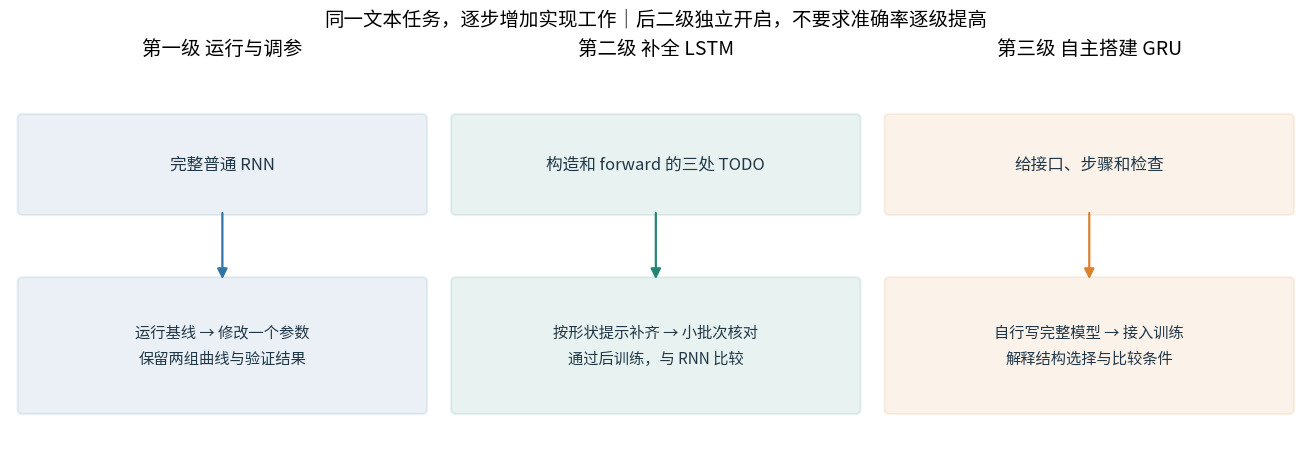

In [2]:
fig = plot_text_levels()
plt.show()
plt.close(fig)


## 先设置本次实验

**所有正式训练参数集中在下一格。**第一次保持默认值，先观察两组普通 RNN 的结果。随后只修改 `TUNE_PARAMETER` 与 `TUNE_VALUE`，记录自己运行前的预测。

| 参数 | 默认值 | 可尝试的课堂范围 | 主要影响 |
|---|---:|---|---|
| `learning_rate` | 0.003 | 0.001、0.0015、0.003、0.005 | 每次更新的步幅，过大可能不稳定 |
| `hidden_size` | 32 | 16、32、64 | 隐藏表示维度、参数量和耗时 |
| `epochs` | 6 | 3、6、10 | 训练轮数；更多轮不保证更好 |
| `batch_size` | 64 | 32、64、128 | 每次更新使用的样本数与每轮更新次数 |
| `max_length` | 100 | 60、100、140 | 保留的前缀长度与计算量；需注意截断 |
| `embedding_dim` | 32 | 16、32、64 | 每个字的向量维度，选做调整 |
| `num_layers` | 1 | 1、2 | 循环层数，选做调整 |

上述范围是操作示例，不是最优参数结论。当前默认调参只把学习率 **0.003 → 0.0015**，其余条件不变。`make_tuned_config` 不接受改成 GRU 来替代第三级实现。

二、三级使用基线预算，便于比较循环结构。第三级若自行选择 E/H/层数/读出，也需同步 `config_level3` 并说明比较条件。一次比较中相同 H 并不表示 RNN/LSTM/GRU 参数量相同。


In [3]:
# 默认只运行第一级；二、三级是独立开关。
RUN_LEVEL2 = False
RUN_LEVEL3 = False
RUN_HISTORICAL_REFERENCE = False  # 只控制末尾两个历史图的重新绘制。

BASE_SETTINGS = dict(
    learning_rate=0.003,
    hidden_size=32,
    epochs=6,
    batch_size=64,
    max_length=100,
    embedding_dim=32,
    num_layers=1,
)
TUNE_PARAMETER = "learning_rate"
TUNE_VALUE = 0.0015
# 以下是示范预测，实验前改成你自己的预测，并保留实际差异。
MY_PREDICTION = "降低学习率可能使学习更平稳，但在相同轮数内也可能学习不足。"

base = TextExperimentConfig(
    name="一级 RNN 基线", cell_type="rnn", readout="last", dropout=0.0,
    seed=42, device="cpu", **BASE_SETTINGS,
)
tuned = make_tuned_config(base, TUNE_PARAMETER, TUNE_VALUE)
config_level2 = replace(base, name="二级 学生 LSTM", cell_type="lstm")
config_level3 = replace(base, name="三级 学生 GRU", cell_type="gru")

RUN_DIR = (LAB_DIR / "outputs" / "text" / "three_levels" /
           (datetime.now().strftime("%Y%m%d_%H%M%S") + "_" + uuid.uuid4().hex[:8]))
RUN_DIR.mkdir(parents=True, exist_ok=False)
results = {}       # 只放真正完成的运行，不预填二、三级成绩。
saved_dirs = {}
print("本次独立运行目录：", RUN_DIR)
print("运行前预测：", MY_PREDICTION)
print("基线配置：", asdict(base))
print("本次调参：", TUNE_PARAMETER, getattr(base, TUNE_PARAMETER), "→", TUNE_VALUE)
(RUN_DIR / "prediction.json").write_text(json.dumps({
    "prediction": MY_PREDICTION, "parameter": TUNE_PARAMETER,
    "before": getattr(base, TUNE_PARAMETER), "after": TUNE_VALUE,
}, ensure_ascii=False, indent=2), encoding="utf-8")


本次独立运行目录： D:\Code_for_all\2026DeeplearningDemo\03_rnn_lab\outputs\text\three_levels\20261019_143359_969208ad
运行前预测： 降低学习率可能使学习更平稳，但在相同轮数内也可能学习不足。
基线配置： {'name': '一级 RNN 基线', 'cell_type': 'rnn', 'embedding_dim': 32, 'hidden_size': 32, 'num_layers': 1, 'dropout': 0.0, 'readout': 'last', 'max_length': 100, 'batch_size': 64, 'epochs': 6, 'learning_rate': 0.003, 'gradient_clip': 1.0, 'seed': 42, 'device': 'cpu'}
本次调参： learning_rate 0.003 → 0.0015


121

## 数据和记录由三级共用

正式数据为现有真实评论的固定 train/val/test 划分；词表只由 **train** 建立，PAD=0、UNK=1。这里只打印标签、规模和诊断，训练与调参都查看验证集，最终测试在最后的独立单元显式开启。

人工短句仅用于说明或接口检查，不能混入正式训练，也不能替代验证指标。样例概率是模型的 softmax 输出，未经校准，不能读成“这个结论有同等程度的可靠性”。


In [4]:
data = load_text_data(DATA_DIR)
vocab = build_vocab(record["text"] for record in data.splits["train"])
assert vocab["<PAD>"] == 0 and vocab["<UNK>"] == 1
print("数据版本：", data.version, "｜类别：", data.class_names)
print("固定划分：", {key: len(rows) for key, rows in data.splits.items()})
print("训练集词表大小：", len(vocab))
print("基线编码诊断：", text_data_diagnostics(data, vocab, base.max_length))

def keep_and_show(key, result):
    # 保存一组真正完成的运行，随后绘图；重跑不会覆盖之前的目录。
    results[key] = result
    destination = save_text_run(result, RUN_DIR / key)
    saved_dirs[key] = destination
    print()
    print(key, result["config"].name)
    print("配置：", asdict(result["config"]))
    print("验证：", {name: round(result["val_metrics"][name], 4)
                       for name in ("loss", "accuracy", "macro_f1")})
    print("参数量：", result["parameter_count"], "｜训练与验证耗时/秒：",
          round(result["elapsed_seconds"], 3), "｜记录目录：", destination)
    for filename, draw in (("training_history.png", plot_text_history),
                           ("validation_confusion.png", plot_text_confusion)):
        fig = draw(result)
        fig.savefig(destination / filename, dpi=140, bbox_inches="tight")
        plt.show()
        plt.close(fig)
    # 按验证集原顺序选择一个正确、两个错误样例，不按概率挑漂亮例子。
    examples = text_examples(result, correct=True, limit=1) + text_examples(result, correct=False, limit=2)
    for example in examples:
        print("验证样例：", example)
    (destination / "validation_examples.json").write_text(
        json.dumps(examples, ensure_ascii=False, indent=2), encoding="utf-8")
    export_text_experiments_csv(list(results.values()), RUN_DIR / "all_experiments.csv")
    return None


数据版本： chnsenticorp-paddlehub-v2.0.0-unique-course-v1 ｜类别： ('负面', '正面')
固定划分： {'train': 2000, 'val': 500, 'test': 500}
训练集词表大小： 3081
基线编码诊断： {'train': {'samples': 2000, 'tokens': 146756, 'truncated_count': 731, 'truncated_fraction': 0.3655, 'unknown_count': 0, 'unknown_fraction': 0.0, 'all_unknown_count': 0, 'empty_count': 0, 'mean_original_length': 109.561}, 'val': {'samples': 500, 'tokens': 36428, 'truncated_count': 196, 'truncated_fraction': 0.392, 'unknown_count': 143, 'unknown_fraction': 0.0039255517733611505, 'all_unknown_count': 0, 'empty_count': 0, 'mean_original_length': 111.826}, 'test': {'samples': 500, 'tokens': 35742, 'truncated_count': 170, 'truncated_fraction': 0.34, 'unknown_count': 99, 'unknown_fraction': 0.0027698505959375523, 'all_unknown_count': 0, 'empty_count': 0, 'mean_original_length': 100.6}}


## 第一级：运行与调参

完整模型是 **字符编号 → Embedding → 普通 RNN → 每句有效句尾 → Linear**。本级无需补代码，`run_course_experiment(..., level=1)` 提供完整普通 RNN，并固定有效 last 读出。

先预测：改小学习率后，相同 6 轮中训练 Loss 会下降得更快还是更慢？验证结果是否同步变化？再运行默认配置和单参数修改配置。图中横轴是轮数，训练 Loss 与验证 Loss 的分离值得关注；混淆矩阵的对角线是分类正确的评论数量。

观察不能只看最终 Accuracy：结合训练曲线、每类错误数和相同评论的预测解释。调参后下降或不变也可以形成有证据的实验结论。


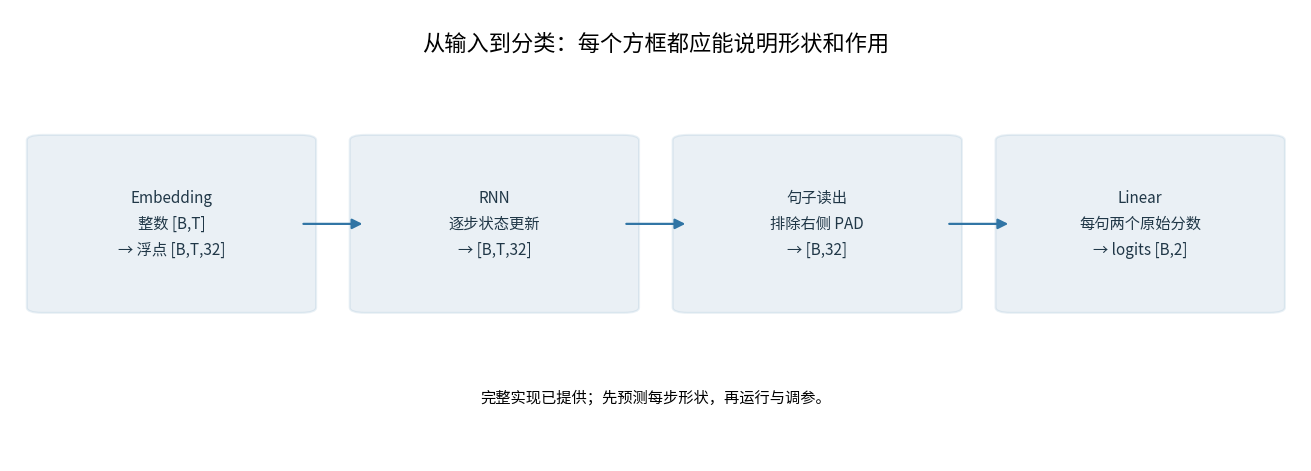

In [5]:
fig = plot_text_model_steps("rnn", base.embedding_dim, base.hidden_size)
plt.show()
plt.close(fig)



L1_baseline 一级 RNN 基线
配置： {'name': '一级 RNN 基线', 'cell_type': 'rnn', 'embedding_dim': 32, 'hidden_size': 32, 'num_layers': 1, 'dropout': 0.0, 'readout': 'last', 'max_length': 100, 'batch_size': 64, 'epochs': 6, 'learning_rate': 0.003, 'gradient_clip': 1.0, 'seed': 42, 'device': 'cpu'}
验证： {'loss': 0.7037, 'accuracy': 0.648, 'macro_f1': 0.6466}
参数量： 100770 ｜训练与验证耗时/秒： 1.121 ｜记录目录： D:\Code_for_all\2026DeeplearningDemo\03_rnn_lab\outputs\text\three_levels\20261019_143359_969208ad\L1_baseline\20261019_143401_1e58a742


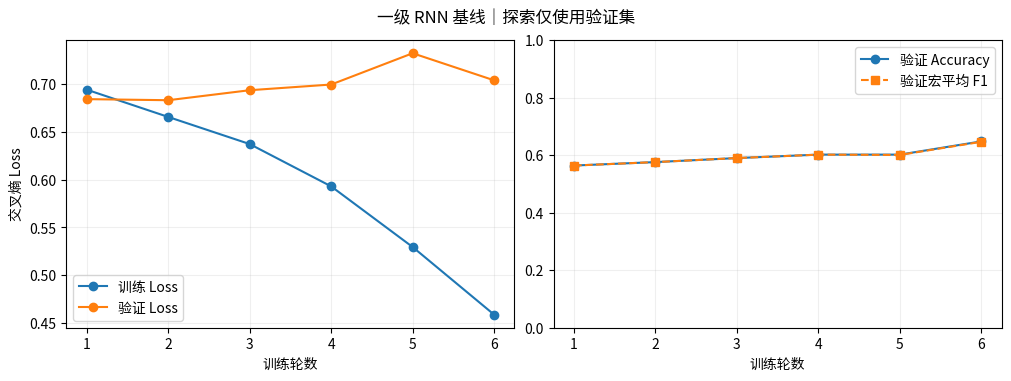

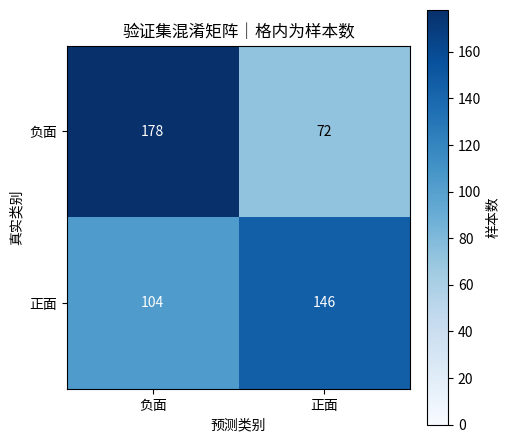

In [6]:
result_baseline = run_course_experiment(base, data, level=1, vocab=vocab)
keep_and_show("L1_baseline", result_baseline)



L1_tuned 一级调参｜learning_rate=0.0015
配置： {'name': '一级调参｜learning_rate=0.0015', 'cell_type': 'rnn', 'embedding_dim': 32, 'hidden_size': 32, 'num_layers': 1, 'dropout': 0.0, 'readout': 'last', 'max_length': 100, 'batch_size': 64, 'epochs': 6, 'learning_rate': 0.0015, 'gradient_clip': 1.0, 'seed': 42, 'device': 'cpu'}
验证： {'loss': 0.6967, 'accuracy': 0.594, 'macro_f1': 0.594}
参数量： 100770 ｜训练与验证耗时/秒： 1.105 ｜记录目录： D:\Code_for_all\2026DeeplearningDemo\03_rnn_lab\outputs\text\three_levels\20261019_143359_969208ad\L1_tuned\20261019_143402_60065bfa


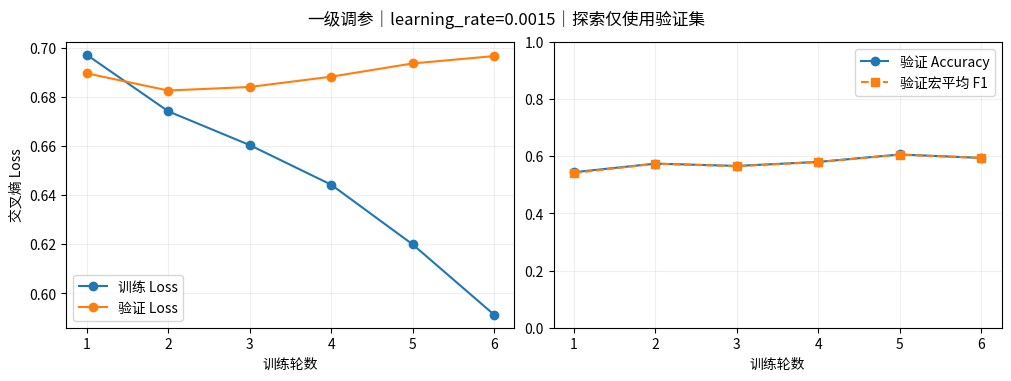

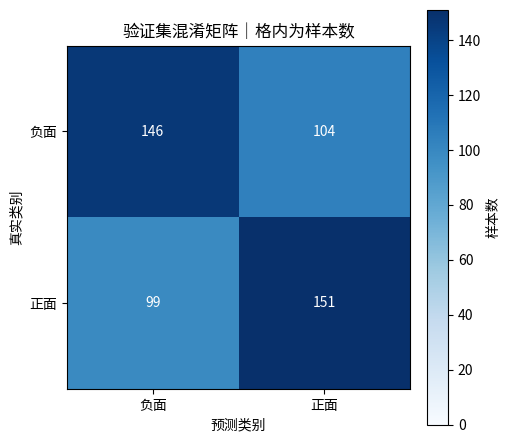

In [7]:
result_tuned = run_course_experiment(tuned, data, level=1, vocab=vocab)
keep_and_show("L1_tuned", result_tuned)


### 把两次运行放在一起看

下图同时列出验证 Accuracy、参数量和耗时。对照配置检查“只改一项”是否成立；耗时会受本机负载影响，单次差异不宜解释得过满。

额外预测使用两句**人工编写短句**，只帮助观察输出，不参与正式指标。写入报告：你改了什么，原先预测是什么，实际曲线与预测有哪些一致或不一致。不要事后改写运行前的预测。


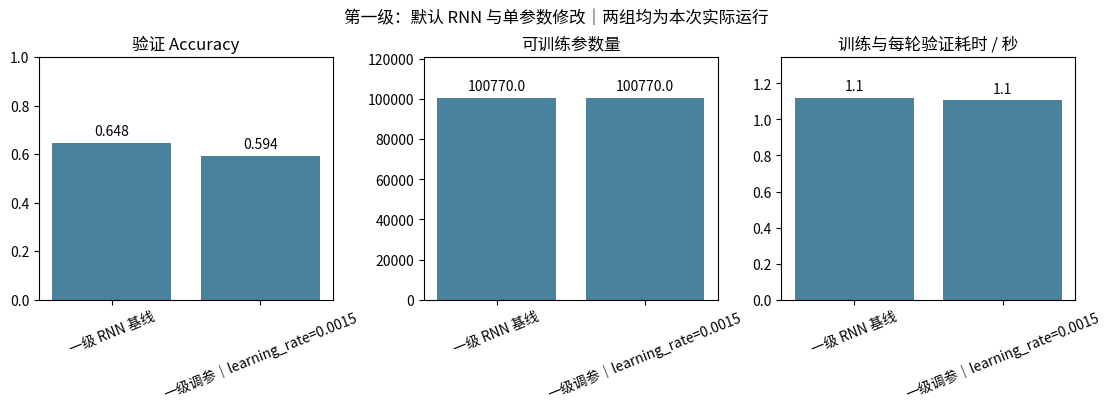

人工句子： 服务很贴心，下次还会再来。
L1_baseline 正面 {'负面': 0.1875525712966919, '正面': 0.8124474287033081} ｜截断： False ｜未知字数： 0
L1_tuned 正面 {'负面': 0.4507889747619629, '正面': 0.5492110252380371} ｜截断： False ｜未知字数： 0
人工句子： 虽然位置不错，但是房间太吵，整晚没有睡好。
L1_baseline 负面 {'负面': 0.8250343799591064, '正面': 0.17496557533740997} ｜截断： False ｜未知字数： 0
L1_tuned 负面 {'负面': 0.7114294767379761, '正面': 0.2885705530643463} ｜截断： False ｜未知字数： 0
第一级两组结果已保存，后两级关闭时无需补任何代码。


In [8]:
fig = plot_text_comparison([results["L1_baseline"], results["L1_tuned"]])
fig.suptitle("第一级：默认 RNN 与单参数修改｜两组均为本次实际运行")
fig.savefig(RUN_DIR / "level1_comparison.png", dpi=140, bbox_inches="tight")
plt.show()
plt.close(fig)

MY_REVIEWS = ["服务很贴心，下次还会再来。", "虽然位置不错，但是房间太吵，整晚没有睡好。"]
for review in MY_REVIEWS:
    print("人工句子：", review)
    for key in ("L1_baseline", "L1_tuned"):
        output = predict_text(results[key], review)
        print(key, output["predicted_class"], output["probabilities"],
              "｜截断：", output["truncated"], "｜未知字数：", output["unknown_count"])
print("第一级两组结果已保存，后两级关闭时无需补任何代码。")


## 第二级：补全 LSTM

在下一格 `StudentLSTMClassifier` 中完成三处 TODO，之后把参数区 `RUN_LEVEL2` 改为 `True`。只补模型代码，词表、训练、绘图和导出仍由公共流程完成。

| TODO | 需要完成 | 输入与输出 | 提示和常见错误 |
|---|---|---|---|
| 1：`build_recurrent` | 构造并返回 LSTM 层 | E→H；配置中的 L 为层数 | 允许 `nn.LSTM`；采用 `batch_first=True`、单向；单层的层间 dropout 为 0。不要把 B/T 当输入维度 |
| 2：`recurrent_steps` | 把字向量送入 LSTM，返回全部时间步输出 | `[B,T,E]`→`[B,T,H]` | LSTM 返回 `output,(h_n,c_n)`。本方法只返回 output；不要把二元组直接送给 Linear |
| 3：`classify_last` | 每句选出有效句尾，送入已提供的分类层 | `[B,T,H]`和`[B]`→`[B,2]` | 可使用按行索引或 gather。长度从 1 开始、位置从 0 开始；索引与张量应在同设备。不要取补齐后的最右列，不提前 softmax |

**小例子**：两句编码后的有效长度为 `[2,4]`，矩形宽度为 4。第一句应取其第 2 个状态，第二句取第 4 个状态；给右侧再加三格 PAD，两个有效位置都不变。这是接口探针，不是训练样本。

检查顺序：先确认 TODO 1 的层属性，再看 TODO 2 的 B/T/H，最后核对 TODO 3 的有效长度。不要用更高准确率来代替接口检查。


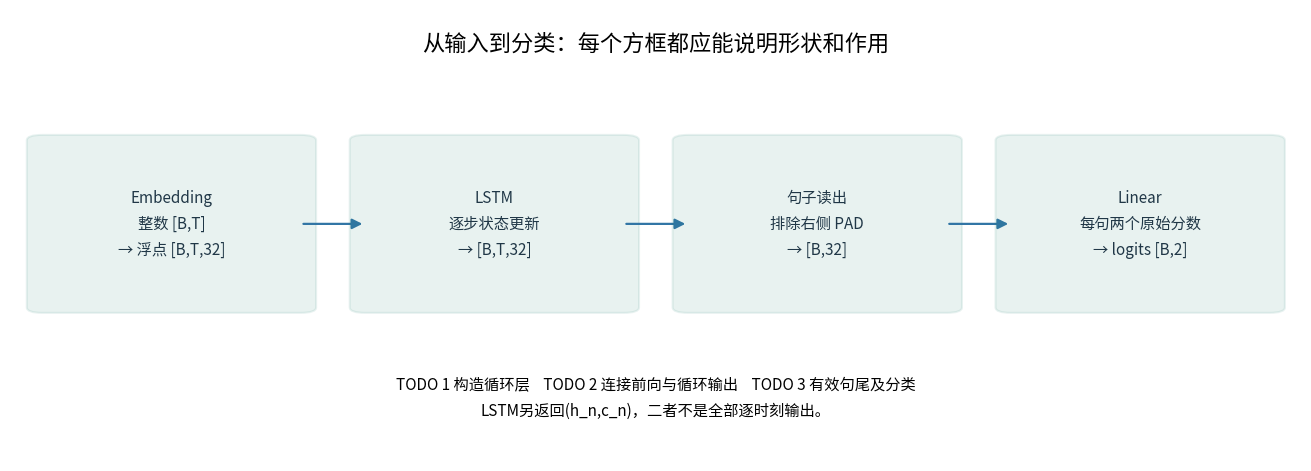

In [9]:
fig = plot_text_model_steps("lstm", config_level2.embedding_dim, config_level2.hidden_size)
plt.show()
plt.close(fig)


In [10]:
class StudentLSTMClassifier(nn.Module):
    def __init__(self, vocab_size, n_classes, config):
        super().__init__()
        self.cell_type = "lstm"
        self.readout = "last"
        self.embedding = nn.Embedding(vocab_size, config.embedding_dim, padding_idx=0)
        self.classifier = nn.Linear(config.hidden_size, n_classes)
        self.recurrent = self.build_recurrent(config)

    def build_recurrent(self, config):
        # TODO 1：返回 E→H 的单向 nn.LSTM，B 在首轴；层数/dropout 与 config 一致。
        # 输入：config；输出：一个 nn.LSTM 层。检查其 input_size/hidden_size/batch_first。
        raise NotImplementedError("二级 TODO 1：请构造并返回 LSTM 层，使用配置中的 E/H/层数。")

    def recurrent_steps(self, embedded):
        # TODO 2：接通已定义循环层，只返回全部时间步 output。
        # 输入：[B,T,E]；输出：[B,T,H]。注意 LSTM 的 (h_n,c_n) 是另一项返回值。
        raise NotImplementedError("二级 TODO 2：请将 Embedding 接入 LSTM，并返回 [B,T,H] 全部输出。")

    def classify_last(self, outputs, lengths):
        # TODO 3：每条按有效长度取句尾，然后使用已经提供的 self.classifier。
        # 输入：[B,T,H] 与 [B]；输出：[B,2] logits；排除 PAD，不使用 softmax。
        raise NotImplementedError("二级 TODO 3：请按每句有效长度读出状态并分类，返回 [B,2] logits。")

    def forward(self, token_ids, lengths):
        embedded = self.embedding(token_ids)
        outputs = self.recurrent_steps(embedded)
        return self.classify_last(outputs, lengths)


### 检查通过，再训练

`check_student_model` 使用人工 ID 小批次检查 `[B,2]`、有限数值、增加右侧 PAD 不变、短句单独/混入长句批次不变。它**不是评分函数，也不评价正式数据**。未补齐时明确停在 TODO；不会自动换成已经完成的教师 LSTM。

结构比较使用基线 RNN 的同一数据、E/H、轮数、学习率和随机种子；不同结构的权重形状不同，固定种子不代表完全相同的初始化。结果需要记录真实参数量。


In [11]:
if RUN_LEVEL2:
    seed_everything(config_level2.seed)
    student_lstm = StudentLSTMClassifier(len(vocab), data.n_classes, config_level2)
    level2_check = check_student_model(student_lstm, data.n_classes, "lstm")
    print("二级人工接口检查：", level2_check)
    result_lstm = run_course_experiment(
        config_level2, data, level=2, vocab=vocab, model=student_lstm)
    keep_and_show("L2_lstm", result_lstm)
    (saved_dirs["L2_lstm"] / "interface_check.json").write_text(
        json.dumps(level2_check, ensure_ascii=False, indent=2), encoding="utf-8")
else:
    print("第二级未开展：打开 RUN_LEVEL2 前，请完成 StudentLSTMClassifier 的 3 处 TODO。")


第二级未开展：打开 RUN_LEVEL2 前，请完成 StudentLSTMClassifier 的 3 处 TODO。


## 第三级：自主搭建 GRU

这一格只提供模型接口，你需要自己搭建完整分类器。可以使用 **`nn.GRU`**，无需手写门控方程、反向传播或优化器。不能继承已完成的公共 `TextClassifier`，也不能通过修改 `cell_type` 调用参考成品来替代本级。

建议按四步完成：

1. **确定输入和输出。**`token_ids` 是 int64 `[B,T]`，`lengths` 是 int64 `[B]`；返回浮点 `[B,2]` 原始 logits。
2. **先画结构。**最小可行方向为 Embedding→单层单向 GRU→有效句尾→Linear。若选择 mean，必须明确排除 PAD。
3. **定义各层并记录设计。**自行设置 `self.embedding`、`self.recurrent`、`self.classifier`；`self.cell_type="gru"`，`self.readout` 记为 `"last"` 或 `"mean"`。这些属性供检查、预测和实验记录使用。
4. **连接 forward，再用小样本检查。**GRU 返回 `output,h_n`，没有 LSTM 的 c_n；有效 last 与 masked mean 都不能把 PAD 混入句子表示。

E/H/层数/读出是你的设计决定，但必须与 `config_level3` 一致。统一接口采用 `batch_first=True`、单向网络；单层层间 dropout 为 0。建议先保持默认预算并实现 last，跑通后再提出有理由的选择。

在下面 Markdown 中先写自己的结构和理由，再实现模型。第三级独立于第二级：即使 LSTM 尚未补完，也可以单独开启 `RUN_LEVEL3`。


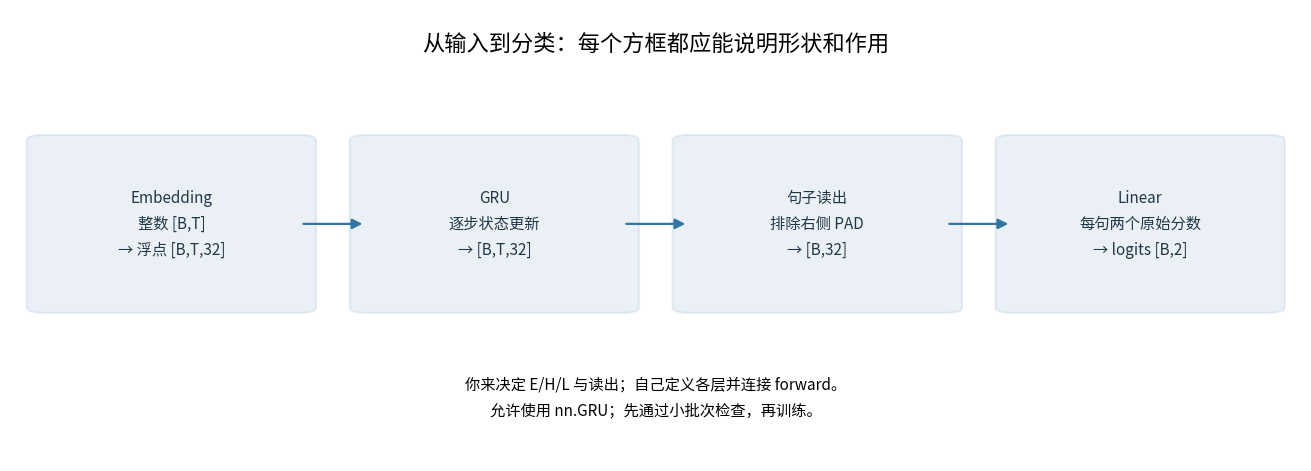

In [12]:
fig = plot_text_model_steps("gru", config_level3.embedding_dim, config_level3.hidden_size)
plt.show()
plt.close(fig)


### 我的设计记录（请编辑本格）

- 结构与读出方式：待填写。
- E、H、层数与参数选择理由：待填写。
- 与基线 RNN 保持一致的条件：待填写。
- 我预计观察到的变化及原因：待填写。

如果你选择不同 E/H/层数或 mean，在参数区同步修改 `config_level3`；不要只改模型却把旧配置写进 CSV。报告允许结构图或结构表，不要求复制所有训练代码。


In [13]:
class StudentGRUClassifier(nn.Module):
    def __init__(self, vocab_size, n_classes, config):
        super().__init__()
        # 自主设计：定义 embedding/recurrent/classifier，记录 cell_type/readout。
        # 允许 nn.GRU；E/H/L/读出需与 config 一致；不能继承完整参考分类器。
        raise NotImplementedError("三级模型构造：请自行定义 Embedding、GRU、分类层及模型属性。")

    def forward(self, token_ids, lengths):
        # 自主设计：从 [B,T] 与 [B] 到 [B,2] logits，正确处理有效长度。
        raise NotImplementedError("三级前向传播：请自行连接各层、处理有效读出，返回 [B,2] logits。")


In [14]:
if RUN_LEVEL3:
    seed_everything(config_level3.seed)
    student_gru = StudentGRUClassifier(len(vocab), data.n_classes, config_level3)
    level3_check = check_student_model(student_gru, data.n_classes, "gru")
    print("三级人工接口检查：", level3_check)
    result_gru = run_course_experiment(
        config_level3, data, level=3, vocab=vocab, model=student_gru)
    keep_and_show("L3_gru", result_gru)
    (saved_dirs["L3_gru"] / "interface_check.json").write_text(
        json.dumps(level3_check, ensure_ascii=False, indent=2), encoding="utf-8")
else:
    print("第三级未开展：请自行实现 StudentGRUClassifier，再打开 RUN_LEVEL3；不依赖第二级。")


第三级未开展：请自行实现 StudentGRUClassifier，再打开 RUN_LEVEL3；不依赖第二级。


## 汇总自己的实际运行，准备一份报告

下图只比较本次真正完成的组，未开展等级不会生成空成绩。`all_experiments.csv` 记录配置、实际循环层、参数量、耗时和验证指标；各组目录保存配置、模型参数、预处理、历史曲线和样例记录。

建议从基础模型中选一条你能解释的验证错例，检查是否截断、是否有未知字、是否存在否定或转折。这里的分组图只帮助看现象，不能单凭相关性断定错误原因。

一份 [实验报告模板](../../docs/03_RNN模型组合探索实验报告模板.docx) 按实际完成内容填写：一级写调参比较；二级追加补全位置和检查；三级追加结构、设计理由与结果。未开展写明即可，不必为每本 Notebook 另交报告。仅提交一份 Word 报告；本人 Notebook、CSV 和必要图留在个人目录备查，不把全部源码与输出堆进 Word。


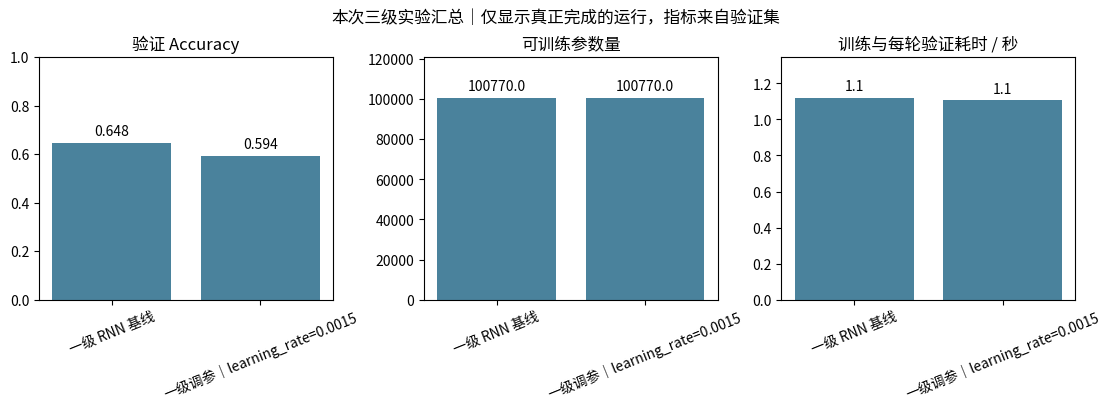

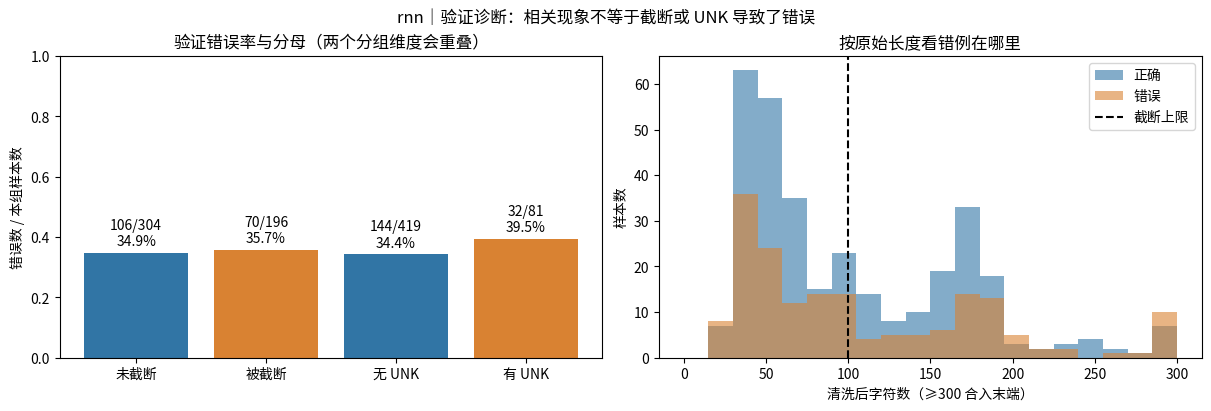

真正完成的运行： ['L1_baseline', 'L1_tuned']
汇总 CSV： D:\Code_for_all\2026DeeplearningDemo\03_rnn_lab\outputs\text\three_levels\20261019_143359_969208ad\all_experiments.csv
各组记录： {'L1_baseline': 'D:\\Code_for_all\\2026DeeplearningDemo\\03_rnn_lab\\outputs\\text\\three_levels\\20261019_143359_969208ad\\L1_baseline\\20261019_143401_1e58a742', 'L1_tuned': 'D:\\Code_for_all\\2026DeeplearningDemo\\03_rnn_lab\\outputs\\text\\three_levels\\20261019_143359_969208ad\\L1_tuned\\20261019_143402_60065bfa'}


In [15]:
fig = plot_text_comparison(list(results.values()))
fig.suptitle("本次三级实验汇总｜仅显示真正完成的运行，指标来自验证集")
fig.savefig(RUN_DIR / "completed_comparison.png", dpi=140, bbox_inches="tight")
plt.show()
plt.close(fig)

fig = plot_validation_groups(results["L1_baseline"])
fig.savefig(RUN_DIR / "level1_validation_groups.png", dpi=140, bbox_inches="tight")
plt.show()
plt.close(fig)

csv_path = export_text_experiments_csv(list(results.values()), RUN_DIR / "all_experiments.csv")
print("真正完成的运行：", list(results))
print("汇总 CSV：", csv_path)
print("各组记录：", {key: str(path) for key, path in saved_dirs.items()})


## 2026-10-17 历史参考：旧任务图与原始输出

以下两幅图是旧版“基础 A / 提高 B / 进阶 C / 手写 D”任务的**教师参考图**，不代表本次三级实验的成绩或完成要求。它们仅用于理解当时的任务拆分和文本流程。

原执行日期为 2026-10-17；原单元 ID 和图片输出保留。第一幅为 `plot_assignment_route("text")` 的旧路线示意，第二幅为 `plot_text_pipeline()` 的流程示意，都是人工绘制的讲解图，不是训练得到的指标。完整原始 Notebook、旧任务代码及来源清单见 [历史快照](reference/20261017/03_自主修改与挑战.ipynb) 与 [快照清单](reference/20261017/manifest.json)。

默认关闭重新绘制；既有图片供直接阅读。若主动开启 `RUN_HISTORICAL_REFERENCE`，只重新画这两幅历史图，不训练参考模型。当前正式任务以本页前面的三个等级为准。


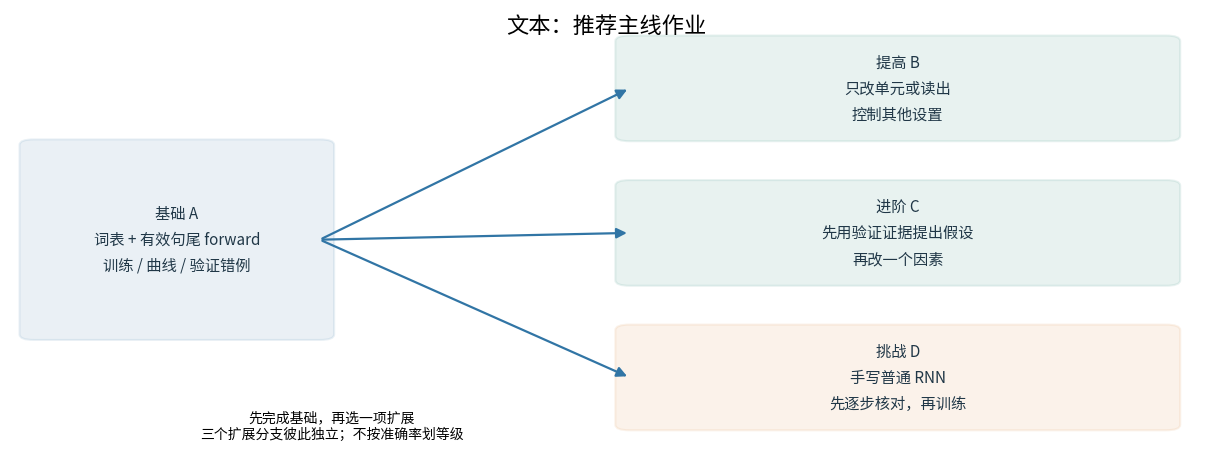

In [2]:
if RUN_HISTORICAL_REFERENCE:
    from rnn_lab.teaching_visuals import plot_assignment_route
    import matplotlib.pyplot as plt

    fig = plot_assignment_route("text")
    plt.show()
    plt.close(fig)


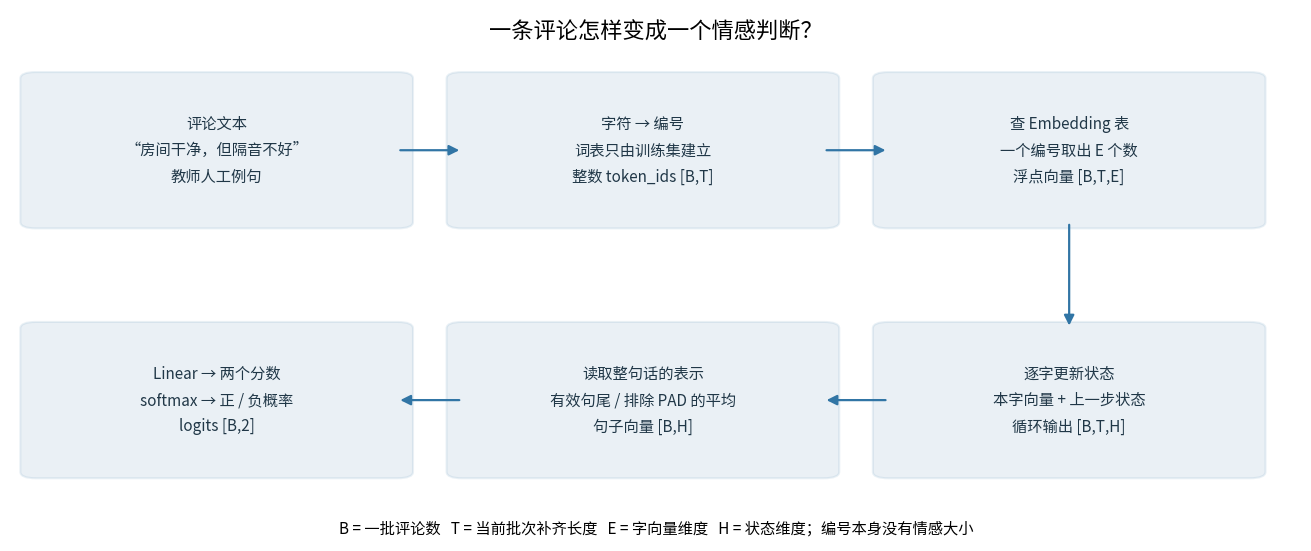

In [3]:
if RUN_HISTORICAL_REFERENCE:
    from rnn_lab.teaching_visuals import plot_text_pipeline
    import matplotlib.pyplot as plt

    fig = plot_text_pipeline()
    plt.show()
    plt.close(fig)


## 最终测试：方案固定后才开启

先根据验证集和实验目的写清选择理由，再指定下面的 `SELECTED_KEY`。这里只评价选定的一组；不根据测试成绩来回改模型或参数。默认 `RUN_FINAL_TEST=False`，CSV 中测试项保持空值，不是 0。

如果只是完成课堂调参和报告，保持关闭即可。所有运行、图和 CSV 已经保存；本页不会自动关闭内核。重新实验时从头运行会创建新的独立目录。


In [18]:
RUN_FINAL_TEST = False
SELECTED_KEY = "L1_baseline"  # 方案固定后填写自己的选择，可为已完成的 L1_tuned/L2_lstm/L3_gru。
SELECTION_REASON = "请在最终测试前填写：基于哪些验证结果和实验目的选定这一组。"
if RUN_FINAL_TEST:
    if SELECTED_KEY not in results:
        raise ValueError("所选运行本次没有完成，请查看 results 中的实际组名。")
    if not SELECTION_REASON.strip() or SELECTION_REASON.startswith("请在最终测试前填写"):
        raise ValueError("请先写清基于验证集的选择理由，再进行最终测试。")
    selected = results[SELECTED_KEY]
    final = evaluate_text_final(selected)
    print("固定方案最终测试：", SELECTED_KEY,
          {key: final[key] for key in ("loss", "accuracy", "macro_f1")})
    (RUN_DIR / "final_selection.json").write_text(json.dumps({
        "selected_key": SELECTED_KEY, "reason": SELECTION_REASON,
        "test_metrics": {key: final[key] for key in ("loss", "accuracy", "macro_f1")},
    }, ensure_ascii=False, indent=2), encoding="utf-8")
    # 含测试的新记录独立保存，不覆盖已经保存的验证记录。
    final_dir = save_text_run(selected, RUN_DIR / "final_selected")
    print("含最终测试的新记录：", final_dir)
else:
    print("最终测试关闭：本次仅使用验证集；已完成记录：", list(results))
export_text_experiments_csv(list(results.values()), RUN_DIR / "all_experiments.csv")
plt.close("all")


最终测试关闭：本次仅使用验证集；已完成记录： ['L1_baseline', 'L1_tuned']
